# Main Fig 5j - relative resting-state power (0.5-5 Hz)

Resting spectral power as fold change relative to each channel's mean locomotion power


In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

In [3]:

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

step_0_root = str(STEPS / "step_0") + "/"


data_root =  str(FIGURES / "figureS5") + "/"


In [4]:
dict_all = {'cm229':{},'cm219':{}}
for mouse in ['cm229','cm219']:
    for behavior_type in ['REST','RUN']:
        dict_all[mouse][behavior_type] = {}
        dict_everything_save = load_pickle(data_root+'csn-thy1-compare-trimmed-{}-'.format(behavior_type) + mouse)
        for key in dict_everything_save.keys():
            dict_all[mouse][behavior_type][key] = dict_everything_save[key]

In [5]:
choice_body_part_dict = dict_all['cm229']['REST']['choice_body_part_dict']
choice_dict = dict_all['cm229']['REST']['choice_dict']
dict_f = dict_all['cm229']['REST']['dict_f']['jrgeco']['RFP_S1']
trimmed_slinn = dict_all['cm229']['REST']['trimmed_dict_slinn']['jrgeco']['RFP_S1']




In [6]:
# avg_trimmed_slinn = trimmed_slinn.copy()
dict_trimmed_slinn = {}
# Average two mice's spectrogram
for behavior_type in ['REST','RUN']:
    dict_trimmed_slinn[behavior_type] = {}
    for fluorophore in ['jrgeco','gcamp']:
        dict_trimmed_slinn[behavior_type][fluorophore] = {}
        for bdp in ['RFP_S1','RFP_M1','RFP_M2']:
            dict_trimmed_slinn[behavior_type][fluorophore][bdp] = {}
            for mouse in ['cm229','cm219']:
                slinn_matrix = dict_all[mouse][behavior_type]['trimmed_dict_slinn'][fluorophore][bdp]
                dict_trimmed_slinn[behavior_type][fluorophore][bdp][mouse] = slinn_matrix


In [7]:
dict_avg_trimmed_slinn = {}
for behavior_type in ['REST','RUN']:
    dict_avg_trimmed_slinn[behavior_type] = {}
    for fluorophore in ['jrgeco','gcamp']:
        dict_avg_trimmed_slinn[behavior_type][fluorophore]={}
        for bdp in ['RFP_S1','RFP_M1','RFP_M2']:
            dict_avg_trimmed_slinn[behavior_type][fluorophore][bdp] = np.concatenate((
                dict_trimmed_slinn[behavior_type][fluorophore][bdp][
                'cm219'],dict_trimmed_slinn[behavior_type][fluorophore][bdp][
                'cm229']),axis=1)
            


--- Statistical Results (on FULL dataset) ---
S1(RFP): Wilcoxon signed-rank test, W = 177.0, p = 1.6728e-29, n = 177 epochs
M1(RFP): Wilcoxon signed-rank test, W = 369.0, p = 3.9329e-28, n = 177 epochs
M2(RFP): Wilcoxon signed-rank test, W = 522.0, p = 4.6030e-27, n = 177 epochs
------------------------------------------


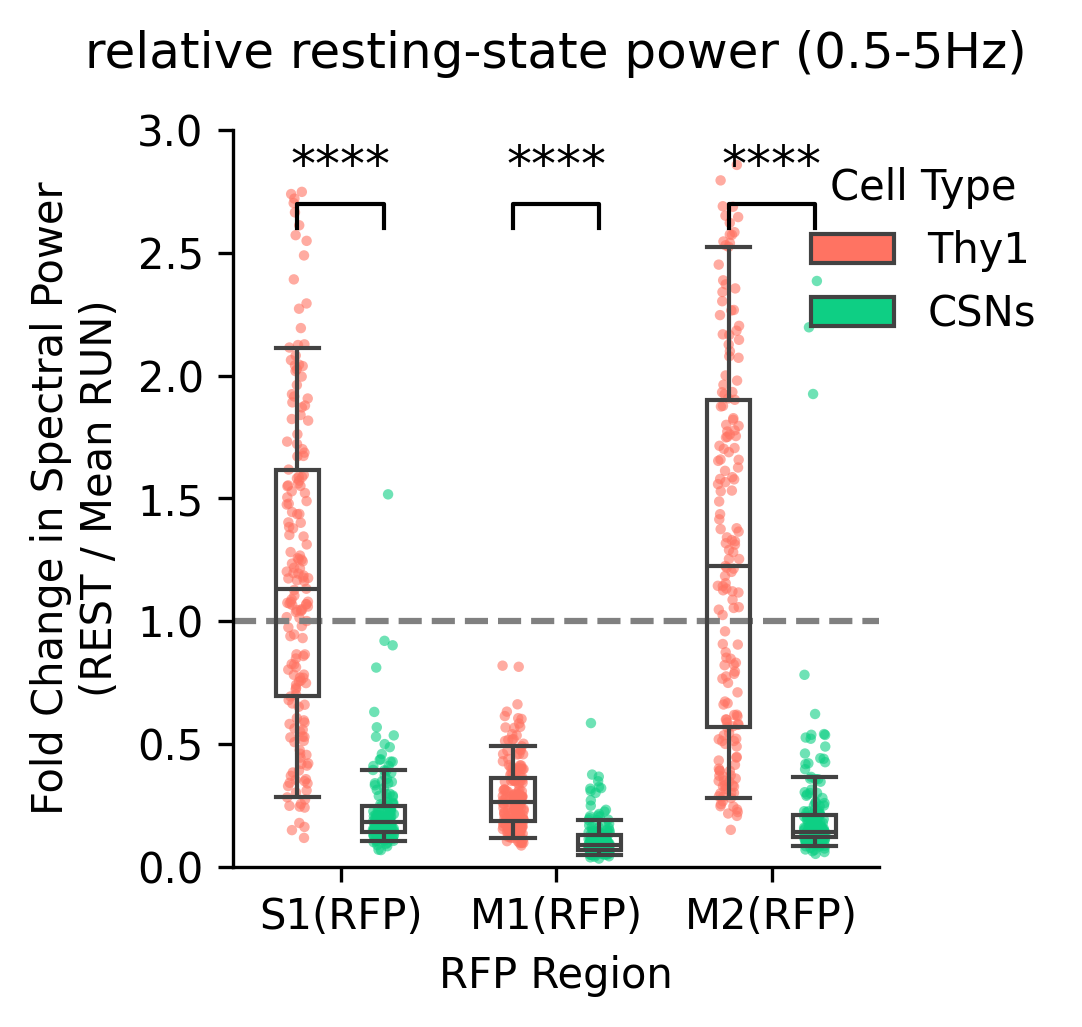

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import pandas as pd
from matplotlib.gridspec import GridSpec
from matplotlib.patches import PathPatch
from matplotlib.collections import PatchCollection

# === 1. Setup & Data Calculation ===

def new_adjust_box_widths(axes, fac=0.9):
    if isinstance(axes, list) is False:
        axes = [axes]
    for ax in axes:
        for c in ax.get_children():
            if isinstance(c, PathPatch) or isinstance(c, PatchCollection):
                if isinstance(c, PathPatch):
                    p = c.get_path()
                else:
                    p = c.get_paths()[-1]
                verts = p.vertices
                verts_sub = verts[:-1]
                xmin = np.min(verts_sub[:, 0])
                xmax = np.max(verts_sub[:, 0])
                xmid = 0.5 * (xmin + xmax)
                xhalf = 0.5 * (xmax - xmin)
                xmin_new = xmid - fac * xhalf
                xmax_new = xmid + fac * xhalf
                verts_sub[verts_sub[:, 0] == xmin, 0] = xmin_new
                verts_sub[verts_sub[:, 0] == xmax, 0] = xmax_new
                for l in ax.lines:
                    try:
                        if np.all(l.get_xdata() == [xmin, xmax]):
                            l.set_xdata([xmin_new, xmax_new])
                    except:
                        pass

# Data Preparation
freq_mask = (dict_f >= 0.5) & (dict_f <= 5.0)
fold_change_data = []
regions = ['S1(RFP)', 'M1(RFP)', 'M2(RFP)']
dict_bdp_keys = ['RFP_S1', 'RFP_M1', 'RFP_M2']

for bdp, region_name in zip(dict_bdp_keys, regions):
    # Get arrays for REST and RUN
    thy1_rest = np.mean(dict_avg_trimmed_slinn['REST']['jrgeco'][bdp][freq_mask, :, :], axis=(0, 2))
    csn_rest = np.mean(dict_avg_trimmed_slinn['REST']['gcamp'][bdp][freq_mask, :, :], axis=(0, 2))
    
    thy1_run = np.mean(dict_avg_trimmed_slinn['RUN']['jrgeco'][bdp][freq_mask, :, :], axis=(0, 2))
    csn_run = np.mean(dict_avg_trimmed_slinn['RUN']['gcamp'][bdp][freq_mask, :, :], axis=(0, 2))
    
    # Calculate the mean of the RUN epochs to use as the baseline denominator
    mean_thy1_run, mean_csn_run = np.mean(thy1_run), np.mean(csn_run)
    
    # FLIPPED MATH: Rest divided by Mean Run
    thy1_fc = thy1_rest / mean_thy1_run
    csn_fc = csn_rest / mean_csn_run
    
    for epoch_idx in range(len(thy1_fc)):
        fold_change_data.append({'Region': region_name, 'Cell_Type': 'Thy1', 'Fold_Change': thy1_fc[epoch_idx], 'Epoch_ID': epoch_idx})
        fold_change_data.append({'Region': region_name, 'Cell_Type': 'CSNs', 'Fold_Change': csn_fc[epoch_idx], 'Epoch_ID': epoch_idx})

df_fc = pd.DataFrame(fold_change_data)

# === 2. Figure Setup & Plotting ===

# Lowered cutoff value since rest/run ratios are much smaller
CUTOFF_VALUE = 10.0  
df_plot = df_fc[df_fc['Fold_Change'] <= CUTOFF_VALUE].copy()

plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(14, 8), dpi=300)
gs = GridSpec(100, 100)

y_offset = 10; x_offset = 10; x_width = 20
ax0 = fig.add_subplot(gs[y_offset:y_offset+40, x_offset:x_offset+x_width])
my_pal = {'Thy1': '#ff7362', 'CSNs': '#0ecf84'}

# Boxplot
sns.boxplot(x="Region", y="Fold_Change", hue="Cell_Type", palette=my_pal,
            data=df_plot, dodge=True, saturation=1, showfliers=False,
            whis=(5, 90), 
            boxprops={'zorder': 5, 'facecolor': 'none'}, linewidth=1, ax=ax0,zorder=7)
new_adjust_box_widths(ax0, fac=0.5)

# Stripplot
sns.stripplot(x="Region", y="Fold_Change", hue="Cell_Type", palette=my_pal,
              data=df_plot, dodge=True, color='dodgerblue', size=2.5, alpha=0.6, zorder=-10,ax=ax0)

# Legend and Baseline (Changed label to 'RUN Baseline')
handles, labels = ax0.get_legend_handles_labels()
ax0.legend(handles[:2], labels[:2], loc='upper right', bbox_to_anchor=(1.3, 1), title="Cell Type", frameon=False)
ax0.axhline(1.0, color='gray', linewidth=1.5, linestyle='dashed', zorder=0, label='RUN Baseline')

# === 3. Statistics & Annotation with Brackets ===

fsz = 12
print("--- Statistical Results (on FULL dataset) ---")

# Lowered Y-limits since the flipped data doesn't spike to 15+
Y_MAX_DISPLAY = 4.0
ax0.set_ylim([0, Y_MAX_DISPLAY]) 

# Adjusted parameters for the statistical brackets
y_bracket = 2.7  # Lowered bracket height
bracket_drop = 0.1 # Shorter vertical ticks
x_offset = 0.2    # Distance from center to the Thy1/CSN centers due to dodging

for i, region in enumerate(regions):
    paired_data = df_fc[df_fc['Region'] == region].pivot(index='Epoch_ID', columns='Cell_Type', values='Fold_Change').dropna()
    thy1_data, csn_data = paired_data['Thy1'], paired_data['CSNs']
    n_pairs = len(paired_data)
    
    stat, p_val = stats.wilcoxon(thy1_data, csn_data)
    print(f"{region}: Wilcoxon signed-rank test, W = {stat:.1f}, p = {p_val:.4e}, n = {n_pairs} epochs")
    
    if p_val < 0.0001: sig_str = "****"
    elif p_val < 0.001: sig_str = "***"
    elif p_val < 0.01: sig_str = "**"
    elif p_val < 0.05: sig_str = "*"
    else: sig_str = "n.s."
    
    # 1. Draw the Bracket
    # x1 (Thy1 left), x2 (CSNs right)
    x1, x2 = i - x_offset, i + x_offset 
    
    # Plot the bracket lines: [left-drop, top-bar, right-drop]
    ax0.plot([x1, x1, x2, x2], [y_bracket - bracket_drop, y_bracket, y_bracket, y_bracket - bracket_drop], 
             lw=1, color='k')
    
    # 2. Place the Star Text
    # Centered above the bracket
    ax0.text(i, y_bracket + 0.05, sig_str, ha='center', va='bottom', color='black', fontsize=fsz)

print("------------------------------------------")

# Axis formatting (Updated labels to reflect the flip)
ax0.set_ylabel('Fold Change in Spectral Power\n(REST / Mean RUN)')
ax0.set_xlabel('RFP Region')
ax0.set_title('relative resting-state power (0.5-5Hz)', y=1.05)
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)
ax0.set_ylim([0,3])
ax0.set_xlim([-0.5,2.5])
plt.savefig('fig5j-relative-resting-power.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Extract exact fold change means and medians for the manuscript
for region in ['S1(RFP)', 'M1(RFP)', 'M2(RFP)']:
    print(f"--- {region} ---")
    thy1_vals = df_fc[(df_fc['Region'] == region) & (df_fc['Cell_Type'] == 'Thy1')]['Fold_Change']
    csn_vals = df_fc[(df_fc['Region'] == region) & (df_fc['Cell_Type'] == 'CSNs')]['Fold_Change']
    
    print(f"Thy1: Mean = {thy1_vals.mean():.2f}x, Median = {thy1_vals.median():.2f}x")
    print(f"CSNs: Mean = {csn_vals.mean():.2f}x, Median = {csn_vals.median():.2f}x\n")

--- S1(RFP) ---
Thy1: Mean = 1.22x, Median = 1.13x
CSNs: Mean = 0.23x, Median = 0.18x

--- M1(RFP) ---
Thy1: Mean = 0.29x, Median = 0.26x
CSNs: Mean = 0.11x, Median = 0.09x

--- M2(RFP) ---
Thy1: Mean = 1.33x, Median = 1.23x
CSNs: Mean = 0.22x, Median = 0.15x

